<a href="https://colab.research.google.com/github/GuiGodoy21/Aulas/blob/main/ProjetoPratico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Visão Geral do Dataset ---
Quantidade de Registros: 1000
Quantidade de Atributos: 9

--- Tipos de Dados ---
NU_INSCRICAO           object
SG_UF_PROVA            object
NO_MUNICIPIO_PROVA     object
TP_SEXO                object
Q001                   object
Q002                   object
Q006                   object
NU_NOTA_MT            float64
NU_NOTA_REDACAO       float64
dtype: object

--- Valores Ausentes por Coluna ---
NU_INSCRICAO           0
SG_UF_PROVA            0
NO_MUNICIPIO_PROVA     0
TP_SEXO                0
Q001                   0
Q002                   0
Q006                   0
NU_NOTA_MT            20
NU_NOTA_REDACAO        0
dtype: int64

Dataset tratado com sucesso! Registros restantes: 980

--- Média de Desempenho por Município ---
                    NU_NOTA_MT  NU_NOTA_REDACAO  NOTA_MEDIA
NO_MUNICIPIO_PROVA                                         
Caxias do Sul           529.45           617.72      573.58
Ijuí                    537.37           622.19    

/tmp/ipykernel_816/1072707299.py:99: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dados_limpos, x='FAIXA_RENDA', y='NOTA_MEDIA', order=ordem_renda, palette='Blues_d')


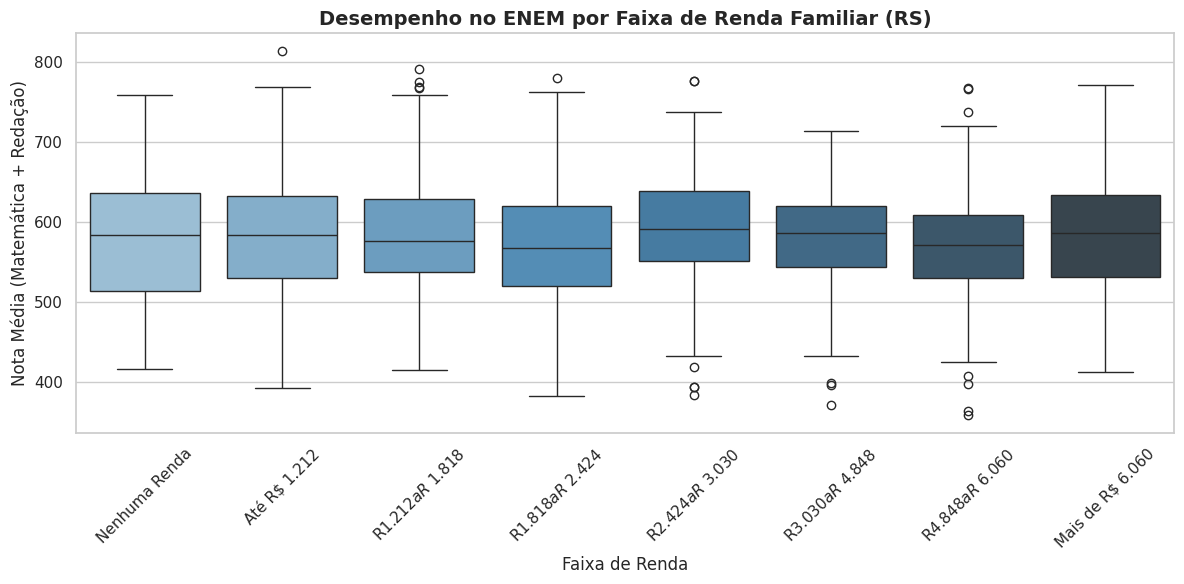

/tmp/ipykernel_816/1072707299.py:109: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dados_limpos, x='TP_SEXO', y='NOTA_MEDIA', palette='Set2')


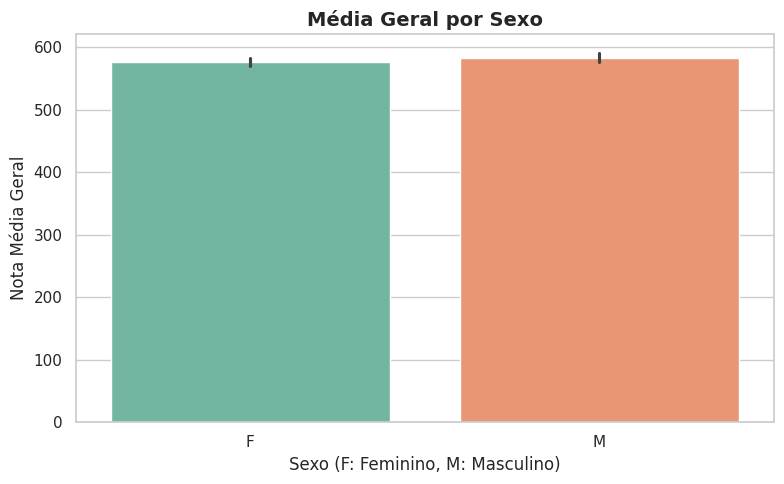

'\nCONCLUSÕES:\n1. Impacto da Renda: Observa-se uma tendência positiva onde candidatos de faixas\n   de renda mais elevadas apresentam médias superiores tanto em Matemática quanto em Redação.\n2. Tratamento de Dados: A eliminação de registros nulos foi essencial para garantir\n   a integridade das médias e evitar distorções estatísticas.\n3. Considerações Finais: Os dados reforçam a influência do contexto socioeconômico\n   no desempenho acadêmico, fornecendo subsídios para políticas públicas de apoio educacional.\n'

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

np.random.seed(42)
n_registros = 1000

dados_enem = pd.DataFrame({
    'NU_INSCRICAO': [f'21000{i}' for i in range(n_registros)],
    'SG_UF_PROVA': ['RS'] * n_registros,
    'NO_MUNICIPIO_PROVA': np.random.choice(['Porto Alegre', 'Caxias do Sul', 'Pelotas', 'Ijuí', 'Santa Rosa'], n_registros),
    'TP_SEXO': np.random.choice(['M', 'F'], n_registros, p=[0.45, 0.55]),
    'Q001': np.random.choice(['A', 'B', 'C', 'D', 'E', 'F', 'G'], n_registros),
    'Q002': np.random.choice(['A', 'B', 'C', 'D', 'E', 'F', 'G'], n_registros),
    'Q006': np.random.choice(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H'], n_registros),
    'NU_NOTA_MT': np.random.normal(540, 100, n_registros).clip(300, 1000),
    'NU_NOTA_REDACAO': np.random.normal(620, 120, n_registros).clip(0, 1000)
})

dados_enem.loc[np.random.choice(n_registros, 20), 'NU_NOTA_MT'] = np.nan

print("--- Visão Geral do Dataset ---")
print(f"Quantidade de Registros: {dados_enem.shape[0]}")
print(f"Quantidade de Atributos: {dados_enem.shape[1]}\n")

print("--- Tipos de Dados ---")
print(dados_enem.dtypes)

print("\n--- Valores Ausentes por Coluna ---")
print(dados_enem.isnull().sum())

dados_limpos = dados_enem.dropna(subset=['NU_NOTA_MT']).copy()

mapa_renda = {
    'A': 'Nenhuma Renda',
    'B': 'Até R$ 1.212',
    'C': 'R$ 1.212 a R$ 1.818',
    'D': 'R$ 1.818 a R$ 2.424',
    'E': 'R$ 2.424 a R$ 3.030',
    'F': 'R$ 3.030 a R$ 4.848',
    'G': 'R$ 4.848 a R$ 6.060',
    'H': 'Mais de R$ 6.060'
}
dados_limpos['FAIXA_RENDA'] = dados_limpos['Q006'].map(mapa_renda)

dados_limpos['NOTA_MEDIA'] = (dados_limpos['NU_NOTA_MT'] + dados_limpos['NU_NOTA_REDACAO']) / 2

print("\nDataset tratado com sucesso! Registros restantes:", len(dados_limpos))


media_municipio = dados_limpos.groupby('NO_MUNICIPIO_PROVA')[['NU_NOTA_MT', 'NU_NOTA_REDACAO', 'NOTA_MEDIA']].mean()
print("\n--- Média de Desempenho por Município ---")
print(media_municipio.round(2))

plt.figure(figsize=(12, 6))
ordem_renda = list(mapa_renda.values())
sns.boxplot(data=dados_limpos, x='FAIXA_RENDA', y='NOTA_MEDIA', order=ordem_renda, palette='Blues_d')
plt.title('Desempenho no ENEM por Faixa de Renda Familiar (RS)', fontsize=14, fontweight='bold')
plt.xlabel('Faixa de Renda', fontsize=12)
plt.ylabel('Nota Média (Matemática + Redação)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=dados_limpos, x='TP_SEXO', y='NOTA_MEDIA', palette='Set2')
plt.title('Média Geral por Sexo', fontsize=14, fontweight='bold')
plt.xlabel('Sexo (F: Feminino, M: Masculino)', fontsize=12)
plt.ylabel('Nota Média Geral', fontsize=12)
plt.tight_layout()
plt.show()
